# Digikala Smart Shopping Assistant — Part 1
## Full-dataset introduction, preprocessing, and exploratory data analysis

This notebook is designed for the **complete** Digikala dataset described in the project brief, not just the 40,000-row examples.

It works with two CSV files:

- `digikala-products.csv`: product-level information.
- `digikala-comments.csv`: user reviews, linked to products through `comments.product_id = products.id`.

### What this notebook does

1. Inspects the source files and checks that the expected columns exist.
2. Preprocesses both CSVs in chunks, so the six-million-plus review table does not have to fit into RAM.
3. Consolidates repeated product IDs **globally** (not independently inside each chunk).
4. Removes exact duplicate review rows globally while preserving conflicting rows for investigation.
5. Creates a DuckDB view of the full review–product join without writing a second huge merged CSV.
6. Produces data-quality tables and EDA charts for products, reviews, and the joined data.
7. Saves cleaned Parquet files, a DuckDB database, and EDA summary tables.

> **Important:** The notebook never changes the original CSV files. It creates cleaned copies in `processed_full/`. Review labels that are missing remain missing; they are not converted to `no_idea`. Outliers are investigated and visualized, not automatically deleted.

### Before running

Put the two complete CSVs in a folder named `data` beside this notebook:

```text
project/
├── Digikala_Part1_Full_Dataset.ipynb
├── data/
│   ├── digikala-products.csv
│   └── digikala-comments.csv
└── processed_full/       # created by this notebook
```

The project brief points to a fixed Hugging Face dataset revision. Use the two full CSVs from that revision, not the 40,000-row example files. If your filenames or folder differ, edit the paths in Section 1.

### Resource notes

- The default chunk size is 100,000 rows. Reduce it to 25,000–50,000 if RAM is limited.
- DuckDB uses disk-backed temporary storage for larger operations. Keep several GB of free disk space in the project folder (more may be needed depending on the source and output sizes).
- The notebook uses **DuckDB + Parquet** for full-data work. It does not load all six million reviews into a single Pandas DataFrame.
- Run the notebook from top to bottom. The full preprocessing step can take time; it is intentionally not run on the 40,000-row examples by default.

## 1. Project data and configuration

The project brief defines the following relationship:

- One product is identified by `products.id`.
- A review refers to its product through `comments.product_id`.
- One product can therefore have many reviews (a one-to-many relationship).

The expected source columns are listed below. Extra columns are preserved as text, while export-index columns such as `Unnamed: 0` are removed.

In [2]:
# Edit these paths if your files are stored somewhere else.
from pathlib import Path

DATA_DIR = Path("data")
PRODUCTS_CSV = DATA_DIR / "digikala-products.csv"
COMMENTS_CSV = DATA_DIR / "digikala-comments.csv"

OUTPUT_DIR = Path("processed_full")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Runtime controls. If your computer has limited RAM, lower CHUNK_SIZE and/or
# DUCKDB_MEMORY_LIMIT. DuckDB can spill intermediate work to TEMP_DIR.
CHUNK_SIZE = 100_000
DUCKDB_MEMORY_LIMIT = "4GB"
DUCKDB_THREADS = 4
TEMP_DIR = OUTPUT_DIR / "duckdb_tmp"
TEMP_DIR.mkdir(parents=True, exist_ok=True)

PRODUCTS_PREPARED = OUTPUT_DIR / "products_prepared.parquet"
COMMENTS_PREPARED = OUTPUT_DIR / "comments_prepared.parquet"
PRODUCTS_CLEAN = OUTPUT_DIR / "products_clean.parquet"
COMMENTS_CLEAN = OUTPUT_DIR / "comments_clean.parquet"
DATABASE_PATH = OUTPUT_DIR / "digikala_analysis.duckdb"

print("Products:", PRODUCTS_CSV.resolve())
print("Comments:", COMMENTS_CSV.resolve())
print("Outputs:", OUTPUT_DIR.resolve())
print("Chunk size:", f"{CHUNK_SIZE:,}")

Products: C:\Users\BiaDigi.com\Documents\bootcamp-quera-files\project\LLM\data\digikala-products.csv
Comments: C:\Users\BiaDigi.com\Documents\bootcamp-quera-files\project\LLM\data\digikala-comments.csv
Outputs: C:\Users\BiaDigi.com\Documents\bootcamp-quera-files\project\LLM\processed_full
Chunk size: 100,000


## 2. Install and import the required packages

`pandas` handles each manageable CSV chunk. `pyarrow` writes Parquet files incrementally. `DuckDB` performs global deduplication, product consolidation, full-data joins, and aggregations without requiring the entire dataset to be held in Pandas memory.

The install cell is safe to rerun; it installs only the packages used in this notebook.

In [3]:
!pip install -q duckdb pyarrow


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import os
import re
import math
import shutil
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

print("pandas:", pd.__version__)
print("DuckDB:", duckdb.__version__)
print("PyArrow:", pa.__version__)

pandas: 2.3.3
DuckDB: 2.0.0
PyArrow: 26.0.1


## 3. Check the input files and their schemas

This cell reads only the CSV headers and a few rows. It does **not** load the complete files. It also validates the required columns against the project brief, so a misspelled filename or unexpected schema is caught before an expensive preprocessing run.

In [5]:
if not PRODUCTS_CSV.exists():
    raise FileNotFoundError(
        f"Products file not found: {PRODUCTS_CSV.resolve()}\n"
        "Put the full digikala-products.csv file in the data/ folder or edit PRODUCTS_CSV."
    )
if not COMMENTS_CSV.exists():
    raise FileNotFoundError(
        f"Comments file not found: {COMMENTS_CSV.resolve()}\n"
        "Put the full digikala-comments.csv file in the data/ folder or edit COMMENTS_CSV."
    )

PRODUCT_COLUMNS = [
    "id", "title_fa", "Rate", "Rate_cnt", "Category1", "Category2",
    "Brand", "Price", "Seller", "Is_Fake", "min_price_last_month", "sub_category"
]
COMMENT_COLUMNS = [
    "id", "title", "body", "created_at", "rate", "recommendation_status",
    "is_buyer", "product_id", "advantages", "disadvantages", "likes", "dislikes",
    "seller_title", "seller_code", "true_to_size_rate"
]

products_header = pd.read_csv(PRODUCTS_CSV, encoding="utf-8-sig", nrows=5, low_memory=False)
comments_header = pd.read_csv(COMMENTS_CSV, encoding="utf-8-sig", nrows=5, low_memory=False)

missing_product_columns = sorted(set(PRODUCT_COLUMNS) - set(products_header.columns))
missing_comment_columns = sorted(set(COMMENT_COLUMNS) - set(comments_header.columns))
if missing_product_columns:
    raise ValueError(f"Missing required product columns: {missing_product_columns}")
if missing_comment_columns:
    raise ValueError(f"Missing required comment columns: {missing_comment_columns}")

print("Products sample shape:", products_header.shape)
print("Comments sample shape:", comments_header.shape)
print("Product columns:", products_header.columns.tolist())
print("Comment columns:", comments_header.columns.tolist())

display(products_header.head(3))
display(comments_header.head(3))

Products sample shape: (5, 12)
Comments sample shape: (5, 15)
Product columns: ['id', 'title_fa', 'Rate', 'Rate_cnt', 'Category1', 'Category2', 'Brand', 'Price', 'Seller', 'Is_Fake', 'min_price_last_month', 'sub_category']
Comment columns: ['id', 'title', 'body', 'created_at', 'rate', 'recommendation_status', 'is_buyer', 'product_id', 'advantages', 'disadvantages', 'likes', 'dislikes', 'seller_title', 'seller_code', 'true_to_size_rate']


,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
0,7096438,آبسلانگ مدل s5 بسته 250 عددی,90,4,آبسلانگ,NaN,متفرقه,634800,سلامت ساز راد,False,0,beauty
1,2845119,آبسلانگ مدل M-1 بسته 400 عددی,84,217,آبسلانگ,NaN,متفرقه,818800,مهر افزون,False,0,beauty
2,6117745,آبسلانگ مدل m50 مجموعه 500 عددی,88,14,آبسلانگ,NaN,متفرقه,920000,یانگوم,False,0,beauty


,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,23 شهریور 1402,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بندی بشه,16 تیر 1399,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خوبه من برای روغن زدم به مژه و لیفت ابرو خریدم,26 مرداد 1401,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN


## 4. Preprocessing choices

These choices are deliberately conservative because the cleaned data will support several later tasks (retrieval, review Q&A, comparison, analytics, and a text classifier).

| Issue | Decision | Reason |
|---|---|---|
| `Unnamed: ...` columns | Remove | These are commonly saved DataFrame indices, not project features. |
| Product IDs repeated | Consolidate globally to one row per `id` | The product search index should contain one product entity per ID. |
| Conflicting product prices | Keep positive minimum, median, and maximum; use the median as representative `Price` | A zero/negative price is not a usable shopping price. Keeping the range makes conflicts auditable. The median is not guaranteed to be the live checkout price. |
| Product rating with no rating count | Keep source value but add `Rate_usable = NULL` when `Rate_cnt <= 0` | A product with no votes should not be interpreted as a true zero-rated product. |
| Persian text variants | Normalize Unicode, Arabic/Persian letter variants, digits, diacritics, and whitespace | Helps exact matching and retrieval without aggressive linguistic transformations. |
| Review title/body | Keep normalized source fields and create `review_text` | The title and body together are useful for retrieval and the later text-only classifier. |
| Advantages/disadvantages | Keep and create `review_text_with_aspects` | They provide optional aspect-level evidence; missing aspects do not remove a review. |
| Missing recommendation label | Preserve as missing | Missing is not equivalent to the explicit `no_idea` class. |
| Duplicated review records | Remove exact duplicate rows globally; report repeated review IDs | Conflicting rows sharing an ID should be inspected, not arbitrarily discarded. |
| Date | Keep original date string and extract Jalali year/month/day where recognizable | Enables trend analysis without pretending a Jalali string is a Gregorian timestamp. |
| Numeric outliers | Flag and inspect; do not automatically delete | Extreme prices or engagement counts can be real. Later modeling may need task-specific filtering. |

The original CSVs remain untouched, so all transformations can be audited or revised.

## 5. Helper functions: Persian text, labels, types, and Jalali dates

Persian normalization here is intentionally light. It does not remove stopwords, punctuation, or negation and does not stem words. Those choices can change meaning and should be tested separately for the retrieval or classification model.

The project data dictionary shows review dates such as `23 شهریور 1402`. We extract Jalali date components from this style and from common numeric Jalali layouts (`1402/06/23` or `23/06/1402`). Unrecognized formats remain missing in the extracted columns, while the original `created_at` text is preserved.

In [6]:
PERSIAN_CHAR_MAP = str.maketrans({
    "ي": "ی", "ى": "ی", "ك": "ک", "ة": "ه", "ۀ": "ه",
    "أ": "ا", "إ": "ا", "ٱ": "ا"
})
DIGIT_MAP = str.maketrans("۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩", "01234567890123456789")
JALALI_MONTHS = {
    "فروردین": 1, "اردیبهشت": 2, "خرداد": 3, "تیر": 4,
    "مرداد": 5, "شهریور": 6, "مهر": 7, "آبان": 8,
    "آذر": 9, "دی": 10, "بهمن": 11, "اسفند": 12
}


def drop_export_index_columns(df):
    """Drop columns generated by exporting a DataFrame index (e.g. Unnamed: 0)."""
    drop_cols = [c for c in df.columns if str(c).strip().lower().startswith("unnamed:")]
    return df.drop(columns=drop_cols, errors="ignore")


def normalize_persian_series(series):
    """Normalize common Persian/Arabic Unicode variants and whitespace."""
    result = series.astype("string")
    result = result.str.normalize("NFC")
    result = result.str.translate(PERSIAN_CHAR_MAP)
    result = result.str.translate(DIGIT_MAP)
    result = result.str.replace("\u0640", "", regex=False)  # tatweel
    result = result.str.replace(r"[\u064B-\u065F\u0670]", "", regex=True)  # vowel marks
    result = result.str.replace(r"\s+", " ", regex=True).str.strip()
    return result.mask(result.eq(""), pd.NA)


def nullable_integer(series):
    """Convert values to nullable Int64; non-numeric/non-integer values become NA."""
    numeric = pd.to_numeric(series, errors="coerce").astype("float64")
    is_integer = numeric.isna() | np.isclose(numeric, np.round(numeric), equal_nan=True)
    numeric = numeric.where(is_integer)
    return numeric.astype("Int64")


def nullable_boolean(series):
    """Convert common true/false spellings to pandas nullable boolean."""
    text = series.astype("string").str.strip().str.lower()
    values = {
        "true": True, "1": True, "yes": True, "y": True, "بله": True,
        "false": False, "0": False, "no": False, "n": False, "خیر": False
    }
    return text.map(values).astype("boolean")


def normalize_recommendation_status(series):
    """Normalize formatting while preserving unknown labels for later inspection."""
    result = series.astype("string").str.strip().str.lower()
    result = result.str.replace(r"[\s-]+", "_", regex=True)
    return result.mask(result.eq(""), pd.NA)


def extract_jalali_parts(series):
    """Return nullable Jalali year, month, day Series extracted from common formats."""
    text = normalize_persian_series(series)
    month_pattern = "|".join(JALALI_MONTHS.keys())

    named = text.str.extract(
        rf"(?P<day>\d{{1,2}})\s+(?P<month_name>{month_pattern})\s+(?P<year>13\d{{2}}|14\d{{2}})"
    )
    ymd = text.str.extract(
        r"(?P<year>13\d{2}|14\d{2})[/-](?P<month>\d{1,2})[/-](?P<day>\d{1,2})"
    )
    dmy = text.str.extract(
        r"(?P<day>\d{1,2})[/-](?P<month>\d{1,2})[/-](?P<year>13\d{2}|14\d{2})"
    )

    year = ymd["year"].fillna(named["year"]).fillna(dmy["year"])
    month = ymd["month"].fillna(named["month_name"].map(JALALI_MONTHS).astype("string")).fillna(dmy["month"])
    day = ymd["day"].fillna(named["day"]).fillna(dmy["day"])

    year = pd.to_numeric(year, errors="coerce").astype("Int64")
    month = pd.to_numeric(month, errors="coerce").astype("Int64")
    day = pd.to_numeric(day, errors="coerce").astype("Int64")

    # Reject impossible month/day components rather than silently accepting them.
    month = month.where(month.between(1, 12))
    day = day.where(day.between(1, 31))
    return year, month, day

print("Preprocessing helpers are ready.")

Preprocessing helpers are ready.


## 6. Chunk-based preprocessing functions

The next two functions read a CSV in chunks and append each processed chunk to a Parquet file. This bounds the Pandas memory footprint. The column types are explicitly standardized between chunks so that the Parquet writer receives a consistent schema.

**Why are duplicates handled later in DuckDB?** A duplicate can appear in two different chunks. Removing duplicates independently inside each chunk would miss cross-chunk duplicates. The later database step performs global deduplication/consolidation.

In [7]:
def standardize_extra_columns_as_text(df, known_columns):
    """Keep unexpected source columns, but force stable text types across chunks."""
    for column in df.columns:
        if column not in known_columns:
            df[column] = df[column].astype("string")
    return df


def preprocess_products_chunk(chunk):
    chunk = drop_export_index_columns(chunk.copy())

    integer_columns = ["id", "Rate_cnt"]
    numeric_columns = ["Rate", "Price", "min_price_last_month"]
    text_columns = [
        "title_fa", "Category1", "Category2", "Brand", "Seller", "sub_category"
    ]

    for column in integer_columns:
        if column in chunk:
            chunk[column] = nullable_integer(chunk[column])
    for column in numeric_columns:
        if column in chunk:
            chunk[column] = pd.to_numeric(chunk[column], errors="coerce").astype("float64")
    for column in text_columns:
        if column in chunk:
            chunk[column] = normalize_persian_series(chunk[column])
    if "Is_Fake" in chunk:
        chunk["Is_Fake"] = nullable_boolean(chunk["Is_Fake"])

    known = set(integer_columns + numeric_columns + text_columns + ["Is_Fake"])
    return standardize_extra_columns_as_text(chunk, known)


def preprocess_comments_chunk(chunk):
    chunk = drop_export_index_columns(chunk.copy())

    integer_columns = ["id", "product_id", "likes", "dislikes"]
    numeric_columns = ["rate", "true_to_size_rate"]
    text_columns = [
        "title", "body", "created_at", "recommendation_status", "advantages",
        "disadvantages", "seller_title", "seller_code"
    ]

    for column in integer_columns:
        if column in chunk:
            chunk[column] = nullable_integer(chunk[column])
    for column in numeric_columns:
        if column in chunk:
            chunk[column] = pd.to_numeric(chunk[column], errors="coerce").astype("float64")
    for column in text_columns:
        if column in chunk:
            chunk[column] = normalize_persian_series(chunk[column])

    if "recommendation_status" in chunk:
        chunk["recommendation_status"] = normalize_recommendation_status(
            chunk["recommendation_status"]
        )
    if "is_buyer" in chunk:
        chunk["is_buyer"] = nullable_boolean(chunk["is_buyer"])

    # Text used by review retrieval and the initial text-only classification baseline.
    title = chunk["title"].fillna("")
    body = chunk["body"].fillna("")
    review_text = (title + " " + body).str.replace(r"\s+", " ", regex=True).str.strip()
    chunk["review_text"] = review_text.mask(review_text.eq(""), pd.NA).astype("string")

    extended = chunk["review_text"].fillna("")
    advantages = chunk["advantages"].fillna("")
    disadvantages = chunk["disadvantages"].fillna("")
    extended = extended + np.where(advantages.ne(""), " نکات مثبت: " + advantages, "")
    extended = extended + np.where(disadvantages.ne(""), " نکات منفی: " + disadvantages, "")
    extended = pd.Series(extended, index=chunk.index, dtype="string")
    extended = extended.str.replace(r"\s+", " ", regex=True).str.strip()
    chunk["review_text_with_aspects"] = extended.mask(extended.eq(""), pd.NA)

    # Jalali date components are additional analysis fields; created_at itself is retained.
    year, month, day = extract_jalali_parts(chunk["created_at"])
    chunk["created_year_jalali"] = year
    chunk["created_month_jalali"] = month
    chunk["created_day_jalali"] = day

    # Lengths are useful for EDA and retrieval diagnostics, not target labels.
    text_for_length = chunk["review_text"].fillna("")
    chunk["review_text_char_count"] = text_for_length.str.len().astype("Int64")
    chunk["review_text_word_count"] = text_for_length.str.count(r"\S+").astype("Int64")

    # Missing and negative engagement counts are not assumed to mean zero.
    for column in ["likes", "dislikes"]:
        if column in chunk:
            chunk[column] = chunk[column].where(chunk[column].isna() | chunk[column].ge(0))
            chunk[f"{column}_log1p"] = np.log1p(chunk[column].astype("float64"))

    known = set(integer_columns + numeric_columns + text_columns + [
        "is_buyer", "review_text", "review_text_with_aspects",
        "created_year_jalali", "created_month_jalali", "created_day_jalali",
        "review_text_char_count", "review_text_word_count", "likes_log1p", "dislikes_log1p"
    ])
    return standardize_extra_columns_as_text(chunk, known)


def csv_chunks_to_parquet(csv_path, output_path, processor, chunksize=100_000):
    """Process a CSV incrementally and write one Parquet file using PyArrow."""
    csv_path = Path(csv_path)
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    if output_path.exists():
        output_path.unlink()

    writer = None
    schema = None
    total_rows = 0
    total_chunks = 0
    try:
        reader = pd.read_csv(
            csv_path,
            encoding="utf-8-sig",
            chunksize=chunksize,
            low_memory=False
        )
        for chunk_number, chunk in enumerate(reader, start=1):
            cleaned = processor(chunk)
            table = pa.Table.from_pandas(cleaned, preserve_index=False)

            if writer is None:
                schema = table.schema
                writer = pq.ParquetWriter(output_path, schema, compression="zstd")
            elif not table.schema.equals(schema, check_metadata=False):
                try:
                    table = table.cast(schema)
                except Exception as exc:
                    raise TypeError(
                        f"Chunk {chunk_number} has a schema different from the first chunk. "
                        "Check the source CSV for mixed types or unexpected columns."
                    ) from exc

            writer.write_table(table)
            total_rows += len(cleaned)
            total_chunks += 1
            print(f"Chunk {chunk_number:,} | rows processed: {total_rows:,}")
    finally:
        if writer is not None:
            writer.close()

    if total_chunks == 0:
        raise ValueError(f"No rows were read from {csv_path}")

    print(f"Saved {total_rows:,} rows to {output_path}")
    return total_rows

## 7. Preprocess the complete products file

This reads the product CSV in chunks to avoid a large Pandas load. The chunks are first written to an intermediate Parquet file. The next DuckDB step consolidates **all** rows by product ID, including repeated IDs that may be far apart in the CSV.

The final representative `Price` is the median of positive observed prices for that product. The minimum and maximum are retained as separate columns. This is a defensible summary for analysis, but it is not proof that the median is the current live price.

In [8]:
product_rows_prepared = csv_chunks_to_parquet(
    csv_path=PRODUCTS_CSV,
    output_path=PRODUCTS_PREPARED,
    processor=preprocess_products_chunk,
    chunksize=CHUNK_SIZE
)
print("Prepared product rows:", f"{product_rows_prepared:,}")

Chunk 1 | rows processed: 100,000
Chunk 2 | rows processed: 200,000
Chunk 3 | rows processed: 300,000
Chunk 4 | rows processed: 400,000
Chunk 5 | rows processed: 500,000
Chunk 6 | rows processed: 600,000
Chunk 7 | rows processed: 700,000
Chunk 8 | rows processed: 800,000
Chunk 9 | rows processed: 900,000
Chunk 10 | rows processed: 1,000,000
Chunk 11 | rows processed: 1,100,000
Chunk 12 | rows processed: 1,200,000
Chunk 13 | rows processed: 1,283,496
Saved 1,283,496 rows to processed_full\products_prepared.parquet
Prepared product rows: 1,283,496


## 8. Preprocess the complete comments file

The comments file is much larger, so it is also processed chunk by chunk. Each review keeps its original `id` and `product_id`, which are important for tracing evidence back to the source.

The two text fields are provided for different purposes:

- `review_text`: normalized title + body. Use this as the initial text-only baseline for the recommendation-status classifier.
- `review_text_with_aspects`: the same text plus optional advantages/disadvantages. This can be tested later for retrieval or as a separate classifier experiment.

Do not use `rate`, `likes`, `dislikes`, product metadata, or the target label as input to a model described as a **text-only** classifier.

In [9]:
comment_rows_prepared = csv_chunks_to_parquet(
    csv_path=COMMENTS_CSV,
    output_path=COMMENTS_PREPARED,
    processor=preprocess_comments_chunk,
    chunksize=CHUNK_SIZE
)
print("Prepared review rows:", f"{comment_rows_prepared:,}")

Chunk 1 | rows processed: 100,000
Chunk 2 | rows processed: 200,000
Chunk 3 | rows processed: 300,000
Chunk 4 | rows processed: 400,000
Chunk 5 | rows processed: 500,000
Chunk 6 | rows processed: 600,000
Chunk 7 | rows processed: 700,000
Chunk 8 | rows processed: 800,000
Chunk 9 | rows processed: 900,000
Chunk 10 | rows processed: 1,000,000
Chunk 11 | rows processed: 1,100,000
Chunk 12 | rows processed: 1,200,000
Chunk 13 | rows processed: 1,300,000
Chunk 14 | rows processed: 1,400,000
Chunk 15 | rows processed: 1,500,000
Chunk 16 | rows processed: 1,600,000
Chunk 17 | rows processed: 1,700,000
Chunk 18 | rows processed: 1,800,000
Chunk 19 | rows processed: 1,900,000
Chunk 20 | rows processed: 2,000,000
Chunk 21 | rows processed: 2,100,000
Chunk 22 | rows processed: 2,200,000
Chunk 23 | rows processed: 2,300,000
Chunk 24 | rows processed: 2,400,000
Chunk 25 | rows processed: 2,500,000
Chunk 26 | rows processed: 2,600,000
Chunk 27 | rows processed: 2,700,000
Chunk 28 | rows processed: 2

## 9. Set up DuckDB for full-data operations

DuckDB will now perform operations that must consider the entire dataset:

- Consolidating repeated product IDs across all chunks.
- Removing exact duplicate review rows across all chunks.
- Checking repeated/conflicting review IDs.
- Joining all comments to product metadata.
- Computing full-data aggregates for EDA.

The full joined dataset is created as a **VIEW** later. A view is a saved query, so it avoids writing another enormous merged CSV or Parquet file unless a later task specifically needs a materialized subset.

In [10]:
# Create/reuse a local DuckDB database. The original CSV files are never modified.
con = duckdb.connect(str(DATABASE_PATH))
con.execute(f"SET memory_limit = '{DUCKDB_MEMORY_LIMIT}'")
con.execute(f"SET threads = {int(DUCKDB_THREADS)}")
con.execute(f"SET temp_directory = '{TEMP_DIR.resolve().as_posix()}'")
con.execute("SET preserve_insertion_order = false")


def sql_path(path):
    """Return a safely single-quoted absolute path for DuckDB SQL."""
    return "'" + str(Path(path).resolve()).replace("\\", "/").replace("'", "''") + "'"

print("DuckDB database:", DATABASE_PATH.resolve())
print("DuckDB memory limit:", DUCKDB_MEMORY_LIMIT)
print("DuckDB threads:", DUCKDB_THREADS)
print("Temporary storage:", TEMP_DIR.resolve())

DuckDB database: C:\Users\BiaDigi.com\Documents\bootcamp-quera-files\project\LLM\processed_full\digikala_analysis.duckdb
DuckDB memory limit: 4GB
DuckDB threads: 4
Temporary storage: C:\Users\BiaDigi.com\Documents\bootcamp-quera-files\project\LLM\processed_full\duckdb_tmp


## 10. Consolidate products globally and deduplicate reviews globally

### Products

For every non-missing `id`, DuckDB creates one output row. Text/category fields use their most frequent non-missing value (`mode`). The largest `Rate_cnt` is retained and the associated `Rate` is selected as the representative score. Positive prices are summarized with minimum, median, and maximum. The median becomes the output `Price`.

`product_source_rows` and `distinct_price_values` make repeated IDs and price conflicts visible. They should not be discarded from the audit trail.

### Reviews

Exact duplicate rows are removed using all columns. We do **not** silently keep an arbitrary row when the same review ID appears with different content. Such repeated IDs are counted in the data-quality section and should be examined before evidence IDs are used downstream.

In [11]:
# Remove old views/files from a previous run so this section can be rerun.
for view_name in ["joined_reviews", "products_clean", "comments_clean"]:
    con.execute(f'DROP VIEW IF EXISTS "{view_name}"')
for output_file in [PRODUCTS_CLEAN, COMMENTS_CLEAN]:
    if output_file.exists():
        output_file.unlink()

# Build one row per product ID. A product ID missing from the source cannot be joined,
# so it is excluded from this product-level table and counted in the QA section.
product_sql = f"""
COPY (
    WITH grouped AS (
        SELECT
            id,
            mode(title_fa) FILTER (WHERE title_fa IS NOT NULL) AS title_fa,
            mode(Category1) FILTER (WHERE Category1 IS NOT NULL) AS Category1,
            mode(Category2) FILTER (WHERE Category2 IS NOT NULL) AS Category2,
            mode(Brand) FILTER (WHERE Brand IS NOT NULL) AS Brand,
            mode(Seller) FILTER (WHERE Seller IS NOT NULL) AS Seller,
            mode(Is_Fake) FILTER (WHERE Is_Fake IS NOT NULL) AS Is_Fake,
            mode(sub_category) FILTER (WHERE sub_category IS NOT NULL) AS sub_category,
            MAX(Rate_cnt) AS Rate_cnt,
            arg_max(Rate, COALESCE(Rate_cnt, -1)) FILTER (WHERE Rate IS NOT NULL) AS Rate,
            MEDIAN(Price) FILTER (WHERE Price > 0) AS Price,
            MIN(Price) FILTER (WHERE Price > 0) AS Price_min_observed,
            MAX(Price) FILTER (WHERE Price > 0) AS Price_max_observed,
            MIN(min_price_last_month) FILTER (WHERE min_price_last_month > 0) AS min_price_last_month,
            COUNT(*) AS product_source_rows,
            COUNT(DISTINCT Price) FILTER (WHERE Price > 0) AS distinct_price_values,
            COUNT(DISTINCT title_fa) FILTER (WHERE title_fa IS NOT NULL) AS distinct_title_values,
            COUNT(DISTINCT Brand) FILTER (WHERE Brand IS NOT NULL) AS distinct_brand_values
        FROM read_parquet({sql_path(PRODUCTS_PREPARED)})
        WHERE id IS NOT NULL
        GROUP BY id
    )
    SELECT
        id, title_fa, Category1, Category2, Brand, Seller, Is_Fake, sub_category,
        Rate, Rate_cnt,
        CASE WHEN COALESCE(Rate_cnt, 0) > 0 THEN Rate ELSE NULL END AS Rate_usable,
        CASE WHEN COALESCE(Rate_cnt, 0) > 0 THEN TRUE ELSE FALSE END AS rating_available,
        Price, Price_min_observed, Price_max_observed, min_price_last_month,
        product_source_rows, distinct_price_values, distinct_title_values,
        distinct_brand_values,
        CASE WHEN distinct_price_values > 1 THEN TRUE ELSE FALSE END AS has_conflicting_prices
    FROM grouped
) TO {sql_path(PRODUCTS_CLEAN)} (FORMAT PARQUET, COMPRESSION ZSTD)
"""
con.execute(product_sql)

# Global exact-row deduplication: this catches duplicates across different CSV chunks.
comments_sql = f"""
COPY (
    SELECT DISTINCT *
    FROM read_parquet({sql_path(COMMENTS_PREPARED)})
) TO {sql_path(COMMENTS_CLEAN)} (FORMAT PARQUET, COMPRESSION ZSTD)
"""
con.execute(comments_sql)

con.execute(f"CREATE OR REPLACE VIEW products_clean AS SELECT * FROM read_parquet({sql_path(PRODUCTS_CLEAN)})")
con.execute(f"CREATE OR REPLACE VIEW comments_clean AS SELECT * FROM read_parquet({sql_path(COMMENTS_CLEAN)})")

print("Saved consolidated products:", PRODUCTS_CLEAN)
print("Saved globally deduplicated comments:", COMMENTS_CLEAN)

Saved consolidated products: processed_full\products_clean.parquet
Saved globally deduplicated comments: processed_full\comments_clean.parquet


## 11. Create the full joined view

The `LEFT JOIN` preserves every cleaned review, including reviews whose `product_id` is absent from the product file. Those rows remain useful for review-text analysis, although they cannot support product/category-level claims.

The product table is one row per `id`, so the join should be many reviews to one product. Do not use an `INNER JOIN` as the default: that would silently remove unmatched reviews from review-level analyses.

In [12]:
con.execute("""
CREATE OR REPLACE VIEW joined_reviews AS
SELECT
    c.*,
    p.title_fa AS product_title,
    p.Category1 AS product_category1,
    p.Category2 AS product_category2,
    p.Brand AS product_brand,
    p.Seller AS product_seller,
    p.sub_category AS product_sub_category,
    p.Price AS product_price,
    p.Rate_usable AS product_rating,
    p.Rate_cnt AS product_rating_count
FROM comments_clean AS c
LEFT JOIN products_clean AS p
    ON c.product_id = p.id
""")

print("Created DuckDB view: joined_reviews")
print("The full joined table has not been exported as another large file.")

Created DuckDB view: joined_reviews
The full joined table has not been exported as another large file.


## 12. Full-dataset size and key-integrity checks

Start by checking the actual full-data counts. This also measures how much data was removed by exact review deduplication and how many product rows were consolidated into unique product IDs.

In [13]:
size_summary = con.execute(f"""
SELECT 'products_prepared' AS dataset, COUNT(*) AS rows FROM read_parquet({sql_path(PRODUCTS_PREPARED)})
UNION ALL
SELECT 'products_clean', COUNT(*) FROM products_clean
UNION ALL
SELECT 'comments_prepared', COUNT(*) FROM read_parquet({sql_path(COMMENTS_PREPARED)})
UNION ALL
SELECT 'comments_clean', COUNT(*) FROM comments_clean
""").df()
display(size_summary)

product_id_quality = con.execute(f"""
SELECT
    (SELECT COUNT(*) FROM read_parquet({sql_path(PRODUCTS_PREPARED)})) AS prepared_product_rows,
    (SELECT COUNT(*) FROM products_clean) AS unique_products_after_consolidation,
    (SELECT COUNT(*) FROM read_parquet({sql_path(PRODUCTS_PREPARED)}) WHERE id IS NULL)
        AS source_rows_with_missing_product_id
""").df()
display(product_id_quality)

comment_id_quality = con.execute("""
SELECT
    COUNT(*) AS cleaned_review_rows,
    COUNT(DISTINCT id) AS unique_non_null_review_ids,
    COUNT(*) FILTER (WHERE id IS NULL) AS null_review_ids
FROM comments_clean
""").df()
display(comment_id_quality)

review_id_duplicates = con.execute("""
WITH repeated AS (
    SELECT id, COUNT(*) AS rows_per_id
    FROM comments_clean
    WHERE id IS NOT NULL
    GROUP BY id
    HAVING COUNT(*) > 1
)
SELECT
    COUNT(*) AS repeated_review_id_groups,
    COALESCE(SUM(rows_per_id - 1), 0) AS extra_rows_with_repeated_review_id
FROM repeated
""").df()
display(review_id_duplicates)

,dataset,rows
0,comments_prepared,6156289
1,products_prepared,1283496
2,products_clean,948352
3,comments_clean,6154908


,prepared_product_rows,unique_products_after_consolidation,source_rows_with_missing_product_id
0,1283496,948352,0


,cleaned_review_rows,unique_non_null_review_ids,null_review_ids
0,6154908,6153060,0


,repeated_review_id_groups,extra_rows_with_repeated_review_id
0,1845,1848.0


## 13. Validate the product–review join

This is one of the most important checks in Part 1. The uploaded example files had limited overlap, but only the **complete** files can establish the real match rate.

We report both row-level review coverage and unique referenced product-ID coverage. Unmatched reviews are not automatically deleted.

In [14]:
join_summary = con.execute("""
SELECT
    COUNT(*) AS total_reviews,
    COUNT(p.id) AS matched_review_rows,
    COUNT(*) - COUNT(p.id) AS unmatched_review_rows,
    ROUND(100.0 * COUNT(p.id) / NULLIF(COUNT(*), 0), 2) AS matched_review_percentage,
    COUNT(DISTINCT c.product_id) AS unique_product_ids_referenced,
    COUNT(DISTINCT p.id) AS unique_referenced_products_matched
FROM comments_clean c
LEFT JOIN products_clean p ON c.product_id = p.id
""").df()
display(join_summary)

join_category_coverage = con.execute("""
SELECT
    COALESCE(p.Category1, 'Unknown / unmatched') AS category,
    COUNT(*) AS review_rows,
    COUNT(p.id) AS matched_review_rows,
    ROUND(100.0 * COUNT(p.id) / NULLIF(COUNT(*), 0), 2) AS match_percentage
FROM comments_clean c
LEFT JOIN products_clean p ON c.product_id = p.id
GROUP BY 1
ORDER BY review_rows DESC
LIMIT 25
""").df()
display(join_category_coverage)

,total_reviews,matched_review_rows,unmatched_review_rows,matched_review_percentage,unique_product_ids_referenced,unique_referenced_products_matched
0,6154908,6154908,0,100.0,331599,331599


,category,review_rows,matched_review_rows,match_percentage
0,اسباب بازی,414786,414786,100.0
1,مراقبت پوست,392099,392099,100.0
2,لباس مردانه,275263,275263,100.0
3,لباس زنانه,246104,246104,100.0
4,اکسسوری زنانه و مردانه,238217,238217,100.0
5,نوشت افزار,226662,226662,100.0
6,برس‌ها و تجهیزات آرایشی,212985,212985,100.0
7,شامپو و مراقبت مو,212639,212639,100.0
8,کتاب شعر و ادبیات,172174,172174,100.0
9,دفتر و کاغذ و مقوا,152332,152332,100.0


## 14. Data dictionary and missing-value report

The next report is calculated from the full cleaned Parquet files. For every column, it gives the data type, number of missing values, and missing percentage. This uses a relatively light aggregate query so it remains practical on the six-million-row review table.

A high missing percentage does not automatically mean that a column should be dropped. For example, `advantages`, `disadvantages`, and `true_to_size_rate` are optional or product-specific fields. Their value depends on the later task.

PRODUCTS — full-data missingness


,column,dtype,missing_count,missing_pct
15,min_price_last_month,DOUBLE,892772,94.14
10,Rate_usable,DOUBLE,587363,61.94
3,Category2,VARCHAR,181346,19.12
5,Seller,VARCHAR,156,0.02
12,Price,DOUBLE,156,0.02
13,Price_min_observed,DOUBLE,156,0.02
14,Price_max_observed,DOUBLE,156,0.02
1,title_fa,VARCHAR,0,0.00
0,id,BIGINT,0,0.00
4,Brand,VARCHAR,0,0.00


COMMENTS — full-data missingness


,column,dtype,missing_count,missing_pct
14,true_to_size_rate,DOUBLE,6154908,100.00
9,disadvantages,VARCHAR,5742705,93.30
8,advantages,VARCHAR,5446829,88.50
1,title,VARCHAR,2865790,46.56
5,recommendation_status,VARCHAR,894249,14.53
12,seller_title,VARCHAR,302104,4.91
13,seller_code,VARCHAR,302104,4.91
2,body,VARCHAR,643,0.01
7,product_id,BIGINT,0,0.00
6,is_buyer,BOOLEAN,0,0.00


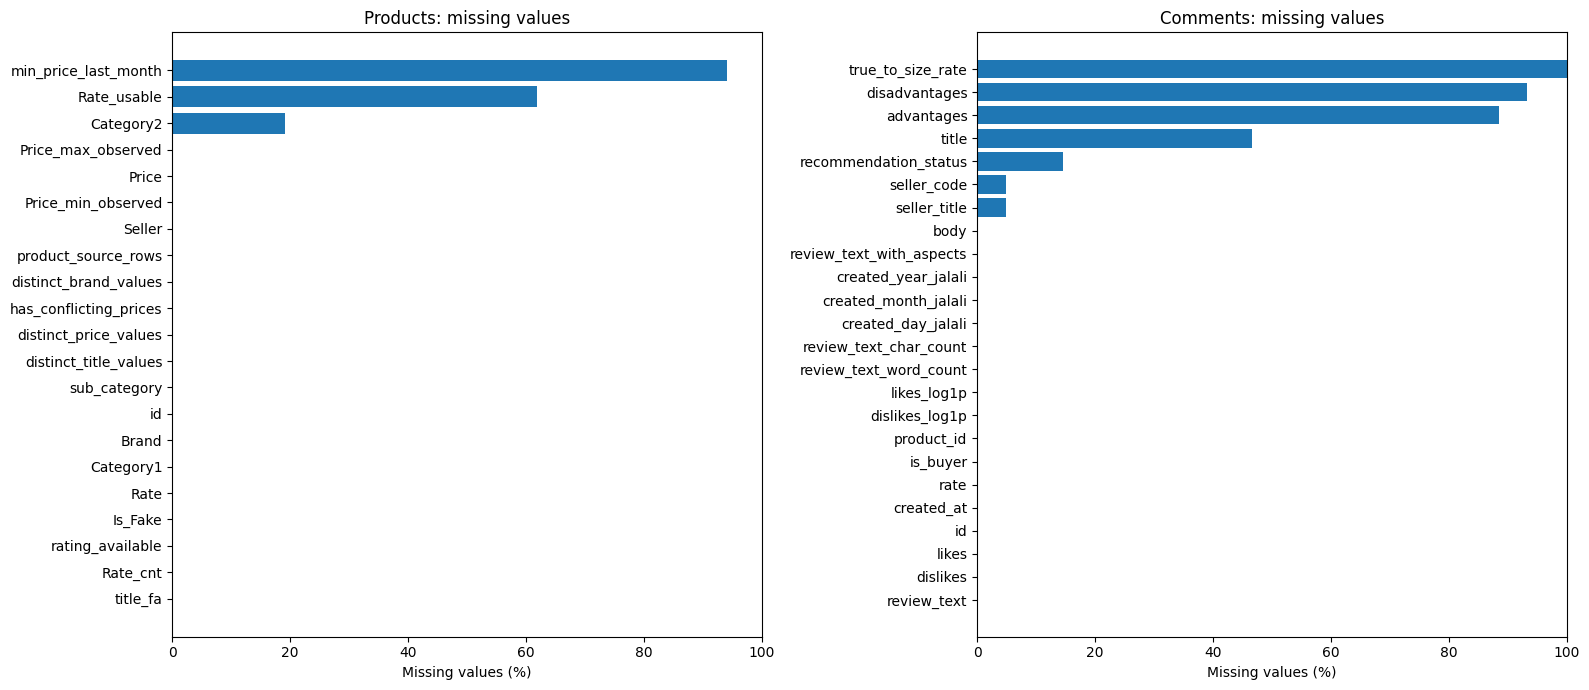

In [15]:
def duckdb_schema_missing_report(view_name):
    """Return schema and missing-value counts/percentages for a DuckDB view."""
    schema = con.execute(f'DESCRIBE SELECT * FROM "{view_name}"').df()
    columns = schema["column_name"].tolist()
    type_map = dict(zip(schema["column_name"], schema["column_type"]))

    expressions = ["COUNT(*) AS total_rows"]
    for column in columns:
        qcol = '"' + column.replace('"', '""') + '"'
        alias = '"' + column.replace('"', '""') + '"'
        expressions.append(f"SUM(CASE WHEN {qcol} IS NULL THEN 1 ELSE 0 END) AS {alias}")

    result = con.execute(
        f'SELECT {", ".join(expressions)} FROM "{view_name}"'
    ).df().iloc[0]
    total = int(result["total_rows"])

    rows = []
    for column in columns:
        missing = int(result[column])
        rows.append({
            "column": column,
            "dtype": type_map.get(column, "unknown"),
            "missing_count": missing,
            "missing_pct": round(100 * missing / total, 2) if total else np.nan
        })
    return pd.DataFrame(rows).sort_values("missing_pct", ascending=False)

products_schema_report = duckdb_schema_missing_report("products_clean")
comments_schema_report = duckdb_schema_missing_report("comments_clean")

print("PRODUCTS — full-data missingness")
display(products_schema_report)
print("COMMENTS — full-data missingness")
display(comments_schema_report)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, report, title in [
    (axes[0], products_schema_report, "Products: missing values"),
    (axes[1], comments_schema_report, "Comments: missing values")
]:
    plot_data = report.sort_values("missing_pct", ascending=True)
    ax.barh(plot_data["column"], plot_data["missing_pct"])
    ax.set_title(title)
    ax.set_xlabel("Missing values (%)")
    ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

## 15. Product data quality and EDA

This section treats the product table as a **product-level** dataset: one row per consolidated product ID. It does not let products with many reviews count more than products with few reviews.

The charts cover category/brand availability, prices, ratings, and duplicate-ID conflicts. Price and rating distributions are also inspected on scales that make skew visible.

Top product categories


,category,products
0,لباس زنانه,77928
1,اکسسوری زنانه,57514
2,لباس مردانه,55970
3,اکسسوری زنانه و مردانه,52644
4,اسباب بازی,42645
5,دخترانه,35260
6,زیورآلات طلا زنانه,32903
7,اکسسوری مردانه,32337
8,کتاب چاپی غیر فارسی,31792
9,دفتر و کاغذ و مقوا,30065


Top brands by number of products


,brand,products
0,متفرقه,530052
1,لیردا,13798
2,الن نار,12308
3,خندالو,7687
4,کرابو,7295
5,اچ اند ام,7075
6,ترمه 1,6534
7,اسمارا,5933
8,27,5220
9,کارانس,5202


Product price summary


,total_products,products_with_positive_price,price_availability_pct,min_positive_price,price_q1,price_median,price_q3,price_p95,max_positive_price
0,948352,948196,99.98,20000.0,740000.0,1700000.0,4584000.0,34830000.0,8.499990e+09


Product rating summary


,total_products,products_with_usable_rating,rating_availability_pct,mean_product_rating,median_product_rating,median_rating_count
0,948352,360989,38.06,79.910042,80.0,0.0


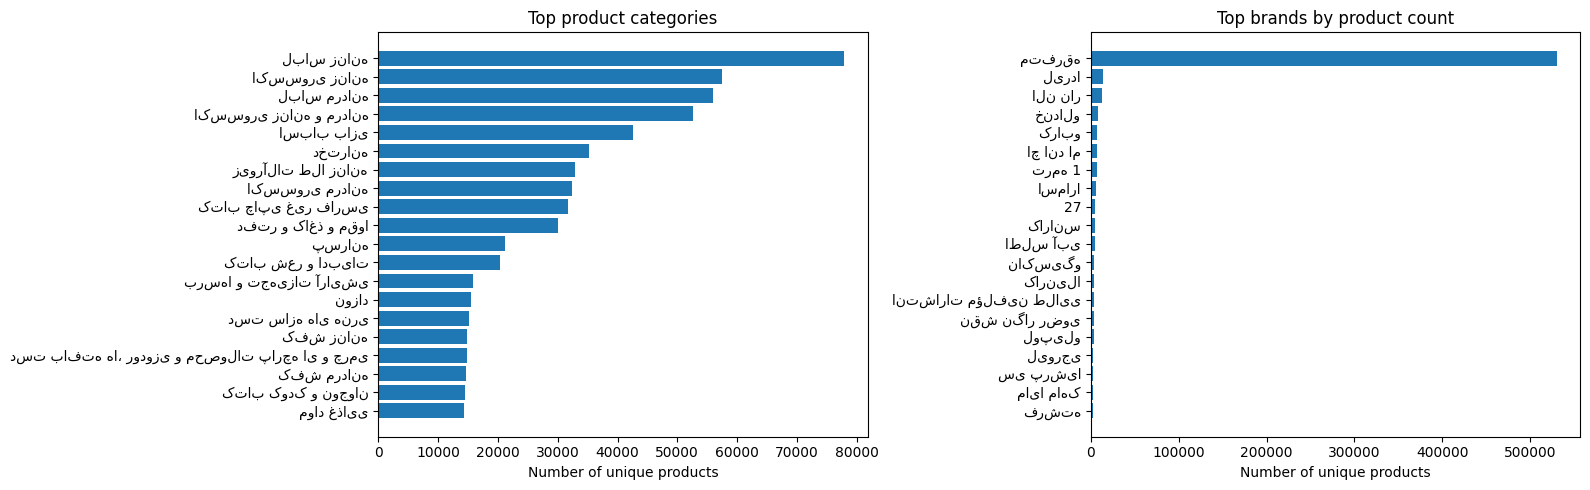

In [16]:
# Product-level summaries.
product_category_counts = con.execute("""
SELECT COALESCE(Category1, 'Missing') AS category, COUNT(*) AS products
FROM products_clean
GROUP BY 1
ORDER BY products DESC
LIMIT 20
""").df()

top_brands = con.execute("""
SELECT COALESCE(Brand, 'Missing') AS brand, COUNT(*) AS products
FROM products_clean
GROUP BY 1
ORDER BY products DESC
LIMIT 20
""").df()

product_price_summary = con.execute("""
SELECT
    COUNT(*) AS total_products,
    COUNT(Price) AS products_with_positive_price,
    ROUND(100.0 * COUNT(Price) / NULLIF(COUNT(*), 0), 2) AS price_availability_pct,
    MIN(Price) AS min_positive_price,
    QUANTILE_CONT(Price, 0.25) AS price_q1,
    MEDIAN(Price) AS price_median,
    QUANTILE_CONT(Price, 0.75) AS price_q3,
    QUANTILE_CONT(Price, 0.95) AS price_p95,
    MAX(Price) AS max_positive_price
FROM products_clean
""").df()

product_rating_summary = con.execute("""
SELECT
    COUNT(*) AS total_products,
    COUNT(Rate_usable) AS products_with_usable_rating,
    ROUND(100.0 * COUNT(Rate_usable) / NULLIF(COUNT(*), 0), 2) AS rating_availability_pct,
    AVG(Rate_usable) AS mean_product_rating,
    MEDIAN(Rate_usable) AS median_product_rating,
    MEDIAN(Rate_cnt) AS median_rating_count
FROM products_clean
""").df()

print("Top product categories")
display(product_category_counts)
print("Top brands by number of products")
display(top_brands)
print("Product price summary")
display(product_price_summary)
print("Product rating summary")
display(product_rating_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(product_category_counts["category"].iloc[::-1], product_category_counts["products"].iloc[::-1])
axes[0].set_title("Top product categories")
axes[0].set_xlabel("Number of unique products")
axes[1].barh(top_brands["brand"].iloc[::-1], top_brands["products"].iloc[::-1])
axes[1].set_title("Top brands by product count")
axes[1].set_xlabel("Number of unique products")
plt.tight_layout()
plt.show()

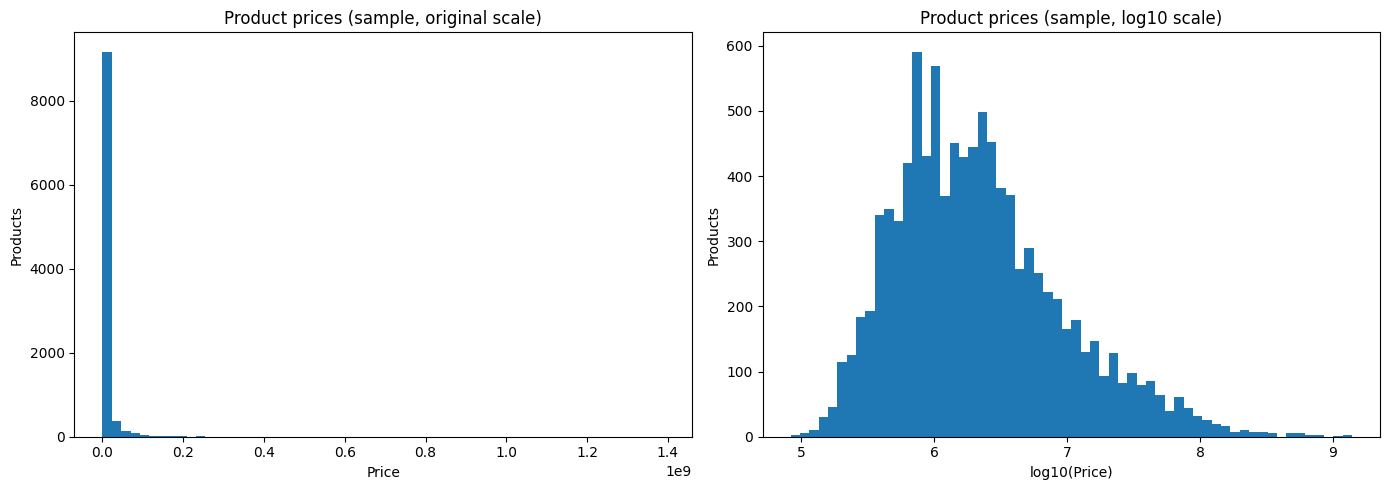

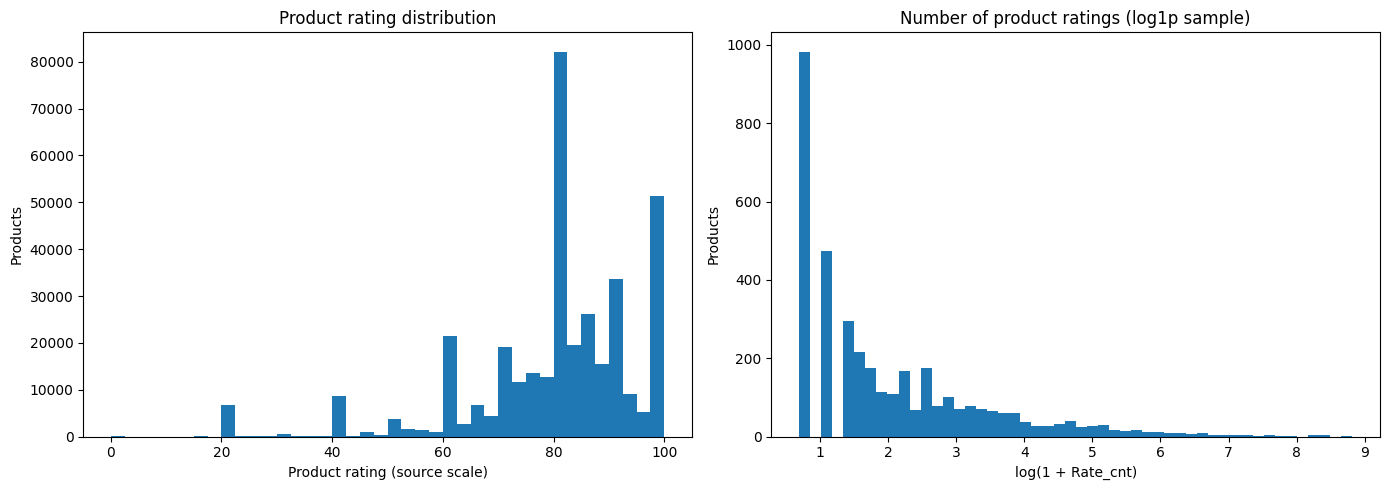

In [17]:
# Price sample: deterministic hash-based selection avoids loading every price into Pandas.
price_sample = con.execute("""
SELECT Price
FROM products_clean
WHERE Price > 0 AND hash(id) % 97 = 0
LIMIT 150000
""").df()["Price"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if len(price_sample):
    axes[0].hist(price_sample, bins=60)
    axes[0].set_title("Product prices (sample, original scale)")
    axes[0].set_xlabel("Price")
    axes[0].set_ylabel("Products")
    axes[1].hist(np.log10(price_sample.clip(lower=1)), bins=60)
    axes[1].set_title("Product prices (sample, log10 scale)")
    axes[1].set_xlabel("log10(Price)")
    axes[1].set_ylabel("Products")
else:
    for ax in axes:
        ax.text(0.5, 0.5, "No positive prices available", ha="center", va="center")
plt.tight_layout()
plt.show()

rating_data = con.execute("""
SELECT Rate_usable AS product_rating
FROM products_clean
WHERE Rate_usable IS NOT NULL
""").df()["product_rating"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if len(rating_data):
    axes[0].hist(rating_data, bins=40)
    axes[0].set_title("Product rating distribution")
    axes[0].set_xlabel("Product rating (source scale)")
    axes[0].set_ylabel("Products")

rating_count_sample = con.execute("""
SELECT Rate_cnt
FROM products_clean
WHERE Rate_cnt > 0 AND hash(id) % 97 = 0
LIMIT 150000
""").df()["Rate_cnt"]
if len(rating_count_sample):
    axes[1].hist(np.log1p(rating_count_sample), bins=50)
    axes[1].set_title("Number of product ratings (log1p sample)")
    axes[1].set_xlabel("log(1 + Rate_cnt)")
    axes[1].set_ylabel("Products")
plt.tight_layout()
plt.show()

### Product price outliers: flag, inspect, do not automatically delete

Prices often have a long right tail. The IQR rule below estimates how many products are above the conventional upper fence. This is a **diagnostic flag**, not an instruction to remove those products: expensive products may be legitimate, and price ranges vary greatly across categories.

In [18]:
price_outlier_report = con.execute("""
WITH bounds AS (
    SELECT
        QUANTILE_CONT(Price, 0.25) AS q1,
        QUANTILE_CONT(Price, 0.75) AS q3
    FROM products_clean
    WHERE Price > 0
), priced_rows AS (
    SELECT Price, q1, q3, q3 - q1 AS iqr
    FROM products_clean CROSS JOIN bounds
    WHERE Price > 0
)
SELECT
    MIN(q1) AS q1,
    MIN(q3) AS q3,
    MIN(iqr) AS iqr,
    MIN(q3 + 1.5 * iqr) AS upper_fence,
    COUNT(*) AS products_with_positive_price,
    COUNT(*) FILTER (WHERE Price > q3 + 1.5 * iqr) AS high_price_outlier_flags,
    ROUND(100.0 * COUNT(*) FILTER (WHERE Price > q3 + 1.5 * iqr) / NULLIF(COUNT(*), 0), 2)
        AS high_price_outlier_percentage
FROM priced_rows
""").df()
display(price_outlier_report)
print("Interpretation: investigate high-price products; do not drop them solely because of the IQR rule.")

,q1,q3,iqr,upper_fence,products_with_positive_price,high_price_outlier_flags,high_price_outlier_percentage
0,740000.0,4584000.0,3844000.0,10350000.0,948196,127941,13.49


Interpretation: investigate high-price products; do not drop them solely because of the IQR rule.


## 16. Review data quality and EDA

This section uses all cleaned review rows, including reviews that could not be joined to a product. That is intentional: text, recommendation labels, dates, and engagement can still be analyzed at review level even when product metadata is missing.

Recommendation status distribution (missing kept separate)


,recommendation_status,review_count
0,recommended,4161846
1,<missing>,894249
2,no_idea,593984
3,not_recommended,504829


Recommendation label quality


,all_reviews,reviews_with_label,missing_label_reviews,reviews_with_expected_label,unexpected_non_missing_labels
0,6154908,5260659,894249,5260659,0


Review rating summary


,reviews_with_rate,minimum_rate,rate_q1,rate_median,rate_mean,rate_q3,maximum_rate,rates_outside_0_to_5
0,6154908,0.0,3.0,4.0,3.648219,5.0,2500.0,1


Review text and optional aspect coverage


,total_reviews,reviews_with_text,text_coverage_pct,median_text_characters,p95_text_characters,median_text_words,p95_text_words,advantages_coverage_pct,disadvantages_coverage_pct
0,6154908,6154859,100.0,35.0,164.0,7.0,34.0,11.5,6.7


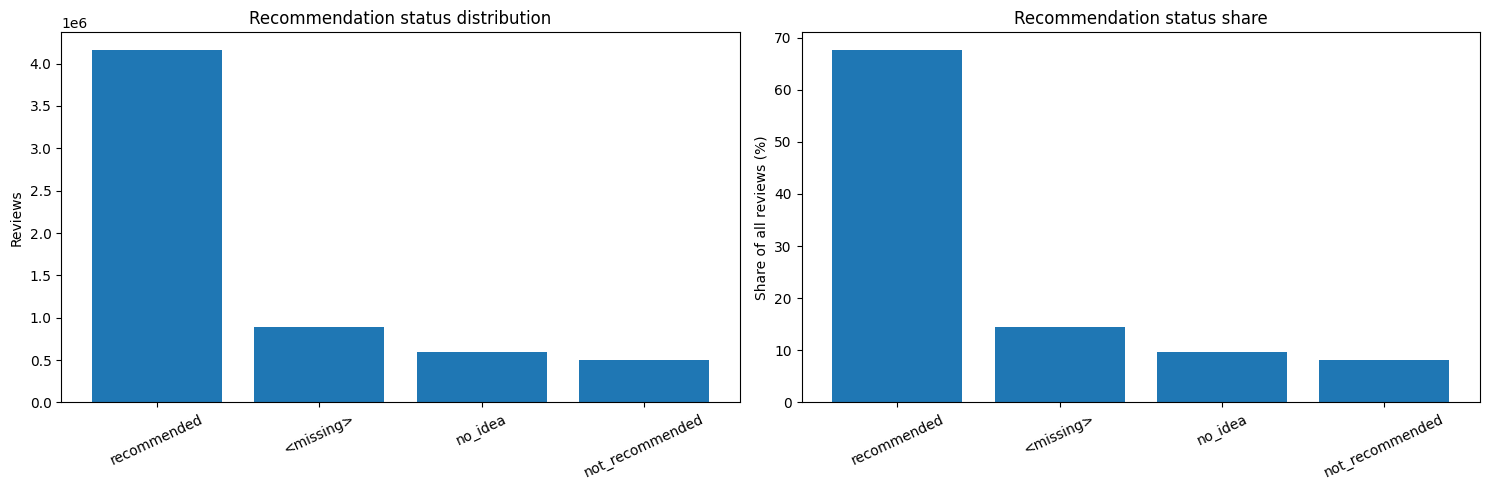

In [19]:
recommendation_counts = con.execute("""
SELECT
    COALESCE(recommendation_status, '<missing>') AS recommendation_status,
    COUNT(*) AS review_count
FROM comments_clean
GROUP BY 1
ORDER BY review_count DESC
""").df()

known_target_summary = con.execute("""
SELECT
    COUNT(*) AS all_reviews,
    COUNT(recommendation_status) AS reviews_with_label,
    COUNT(*) FILTER (WHERE recommendation_status IS NULL) AS missing_label_reviews,
    COUNT(*) FILTER (WHERE recommendation_status IN ('recommended', 'not_recommended', 'no_idea'))
        AS reviews_with_expected_label,
    COUNT(*) FILTER (WHERE recommendation_status IS NOT NULL
        AND recommendation_status NOT IN ('recommended', 'not_recommended', 'no_idea'))
        AS unexpected_non_missing_labels
FROM comments_clean
""").df()

review_rate_summary = con.execute("""
SELECT
    COUNT(rate) AS reviews_with_rate,
    MIN(rate) AS minimum_rate,
    QUANTILE_CONT(rate, 0.25) AS rate_q1,
    MEDIAN(rate) AS rate_median,
    AVG(rate) AS rate_mean,
    QUANTILE_CONT(rate, 0.75) AS rate_q3,
    MAX(rate) AS maximum_rate,
    COUNT(*) FILTER (WHERE rate < 0 OR rate > 5) AS rates_outside_0_to_5
FROM comments_clean
""").df()

review_text_summary = con.execute("""
SELECT
    COUNT(*) AS total_reviews,
    COUNT(review_text) AS reviews_with_text,
    ROUND(100.0 * COUNT(review_text) / NULLIF(COUNT(*), 0), 2) AS text_coverage_pct,
    MEDIAN(review_text_char_count) AS median_text_characters,
    QUANTILE_CONT(review_text_char_count, 0.95) AS p95_text_characters,
    MEDIAN(review_text_word_count) AS median_text_words,
    QUANTILE_CONT(review_text_word_count, 0.95) AS p95_text_words,
    ROUND(100.0 * COUNT(*) FILTER (WHERE advantages IS NOT NULL) / NULLIF(COUNT(*), 0), 2)
        AS advantages_coverage_pct,
    ROUND(100.0 * COUNT(*) FILTER (WHERE disadvantages IS NOT NULL) / NULLIF(COUNT(*), 0), 2)
        AS disadvantages_coverage_pct
FROM comments_clean
""").df()

print("Recommendation status distribution (missing kept separate)")
display(recommendation_counts)
print("Recommendation label quality")
display(known_target_summary)
print("Review rating summary")
display(review_rate_summary)
print("Review text and optional aspect coverage")
display(review_text_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(recommendation_counts["recommendation_status"], recommendation_counts["review_count"])
axes[0].set_title("Recommendation status distribution")
axes[0].set_ylabel("Reviews")
axes[0].tick_params(axis="x", rotation=25)
axes[1].bar(recommendation_counts["recommendation_status"],
            recommendation_counts["review_count"] / recommendation_counts["review_count"].sum() * 100)
axes[1].set_title("Recommendation status share")
axes[1].set_ylabel("Share of all reviews (%)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

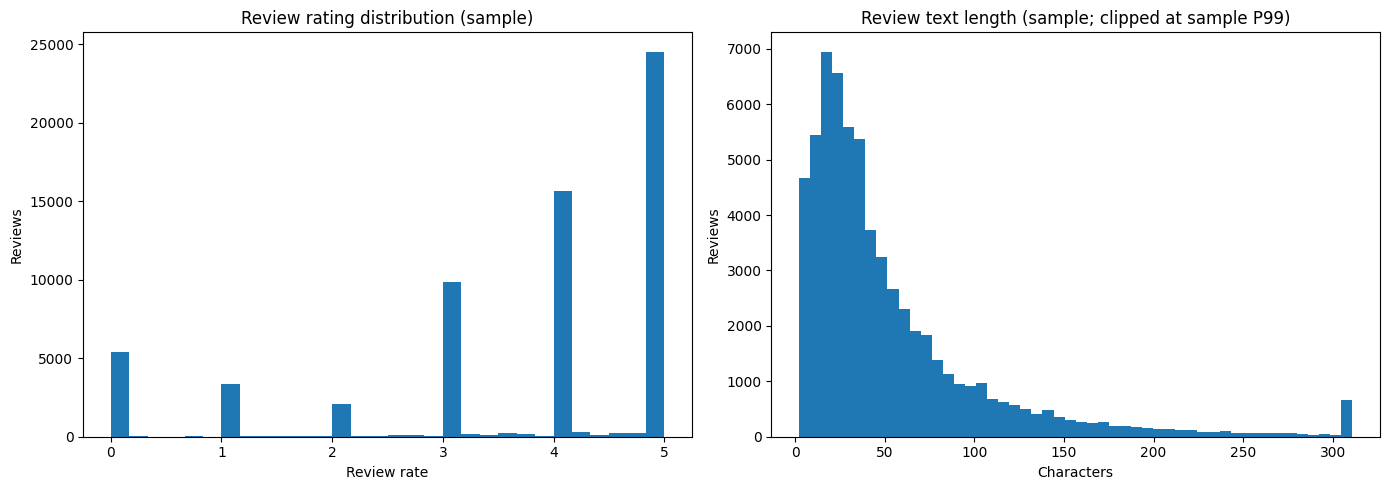

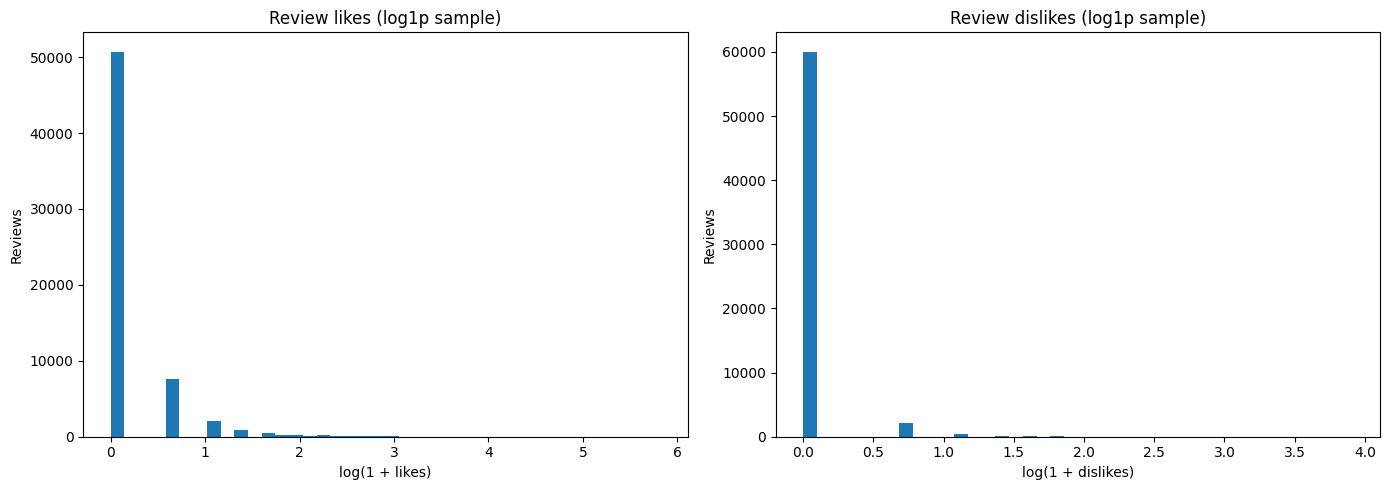

In [20]:
# Review ratings. The data dictionary does not specify the rating scale, so the summary above
# also reports the observed minimum/maximum and values outside a common 0–5 range.
review_rates = con.execute("""
SELECT rate FROM comments_clean WHERE rate IS NOT NULL AND hash(id) % 97 = 0 LIMIT 200000
""").df()["rate"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if len(review_rates):
    axes[0].hist(review_rates, bins=30)
    axes[0].set_title("Review rating distribution (sample)")
    axes[0].set_xlabel("Review rate")
    axes[0].set_ylabel("Reviews")

text_lengths = con.execute("""
SELECT review_text_char_count
FROM comments_clean
WHERE review_text IS NOT NULL AND hash(id) % 97 = 0
LIMIT 200000
""").df()["review_text_char_count"].dropna()
if len(text_lengths):
    axes[1].hist(text_lengths.clip(upper=text_lengths.quantile(0.99)), bins=50)
    axes[1].set_title("Review text length (sample; clipped at sample P99)")
    axes[1].set_xlabel("Characters")
    axes[1].set_ylabel("Reviews")
plt.tight_layout()
plt.show()

engagement_sample = con.execute("""
SELECT likes_log1p, dislikes_log1p
FROM comments_clean
WHERE (likes_log1p IS NOT NULL OR dislikes_log1p IS NOT NULL)
  AND hash(id) % 97 = 0
LIMIT 200000
""").df()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if not engagement_sample.empty:
    axes[0].hist(engagement_sample["likes_log1p"].dropna(), bins=40)
    axes[0].set_title("Review likes (log1p sample)")
    axes[0].set_xlabel("log(1 + likes)")
    axes[0].set_ylabel("Reviews")
    axes[1].hist(engagement_sample["dislikes_log1p"].dropna(), bins=40)
    axes[1].set_title("Review dislikes (log1p sample)")
    axes[1].set_xlabel("log(1 + dislikes)")
    axes[1].set_ylabel("Reviews")
plt.tight_layout()
plt.show()

### Review dates and activity over time

The source uses Jalali date strings. The year/month charts use only dates that matched one of the supported patterns. The parsing-coverage percentage tells you how much of the date column was usable; it is important to report this rather than silently assuming every row was parsed.

Jalali date parsing coverage


,total_reviews,parsed_jalali_years,parsed_year_percentage
0,6154908,6154908,100.0


Reviews per Jalali year


,jalali_year,review_count
0,1395,3562
1,1396,6343
2,1397,16683
3,1398,138598
4,1399,684195
5,1400,1253378
6,1401,2165539
7,1402,1886610


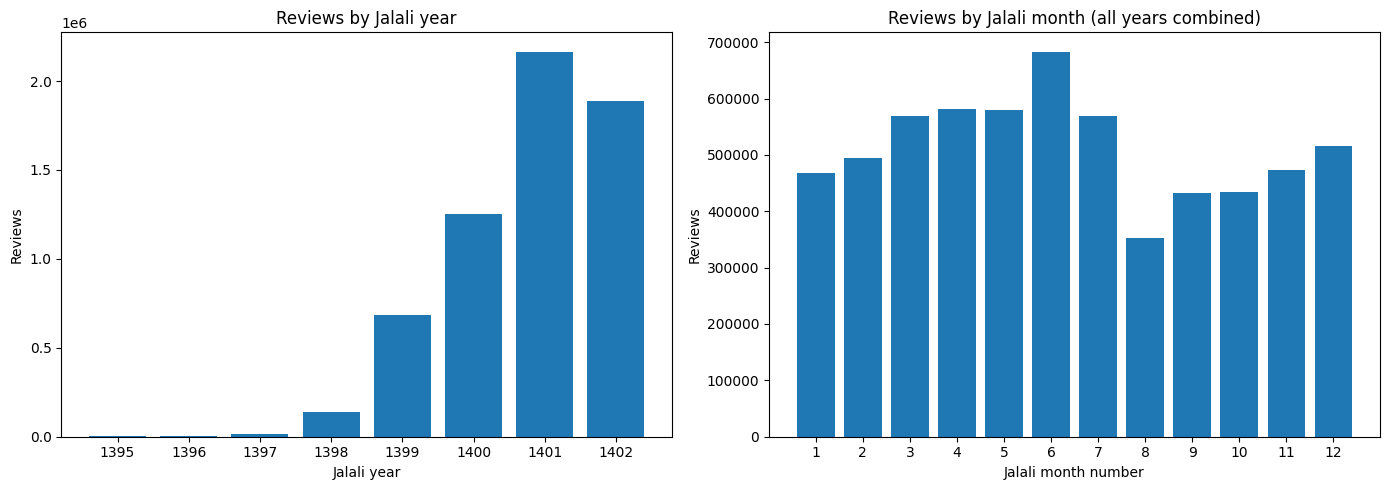

In [21]:
date_coverage = con.execute("""
SELECT
    COUNT(*) AS total_reviews,
    COUNT(created_year_jalali) AS parsed_jalali_years,
    ROUND(100.0 * COUNT(created_year_jalali) / NULLIF(COUNT(*), 0), 2) AS parsed_year_percentage
FROM comments_clean
""").df()

year_counts = con.execute("""
SELECT created_year_jalali AS jalali_year, COUNT(*) AS review_count
FROM comments_clean
WHERE created_year_jalali IS NOT NULL
GROUP BY 1
ORDER BY 1
""").df()

month_counts = con.execute("""
SELECT created_month_jalali AS jalali_month, COUNT(*) AS review_count
FROM comments_clean
WHERE created_month_jalali IS NOT NULL
GROUP BY 1
ORDER BY 1
""").df()

print("Jalali date parsing coverage")
display(date_coverage)
print("Reviews per Jalali year")
display(year_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if len(year_counts):
    axes[0].bar(year_counts["jalali_year"].astype(str), year_counts["review_count"])
    axes[0].set_title("Reviews by Jalali year")
    axes[0].set_xlabel("Jalali year")
    axes[0].set_ylabel("Reviews")
if len(month_counts):
    axes[1].bar(month_counts["jalali_month"].astype(str), month_counts["review_count"])
    axes[1].set_title("Reviews by Jalali month (all years combined)")
    axes[1].set_xlabel("Jalali month number")
    axes[1].set_ylabel("Reviews")
plt.tight_layout()
plt.show()

### Common Persian terms in review text (exploratory only)

The following token-frequency view uses a deterministic sample of reviews so it does not pull millions of text rows into Python. It removes a small, transparent list of very common Persian function words only for this chart. This is **not** the text-cleaning rule used in the stored data; the actual `review_text` preserves words, punctuation, and negation.

Do not interpret raw frequent words as product aspects without context. A phrase-level or aspect-based analysis is better for the manager analytics part.

,token,sample_frequency
0,خوب,7122
1,عالی,5788
2,خوبه,5590
3,کیفیت,3102
4,قیمت,2545
5,نیست,1923
6,خوبی,1897
7,استفاده,1891
8,عالیه,1882
9,کتاب,1814


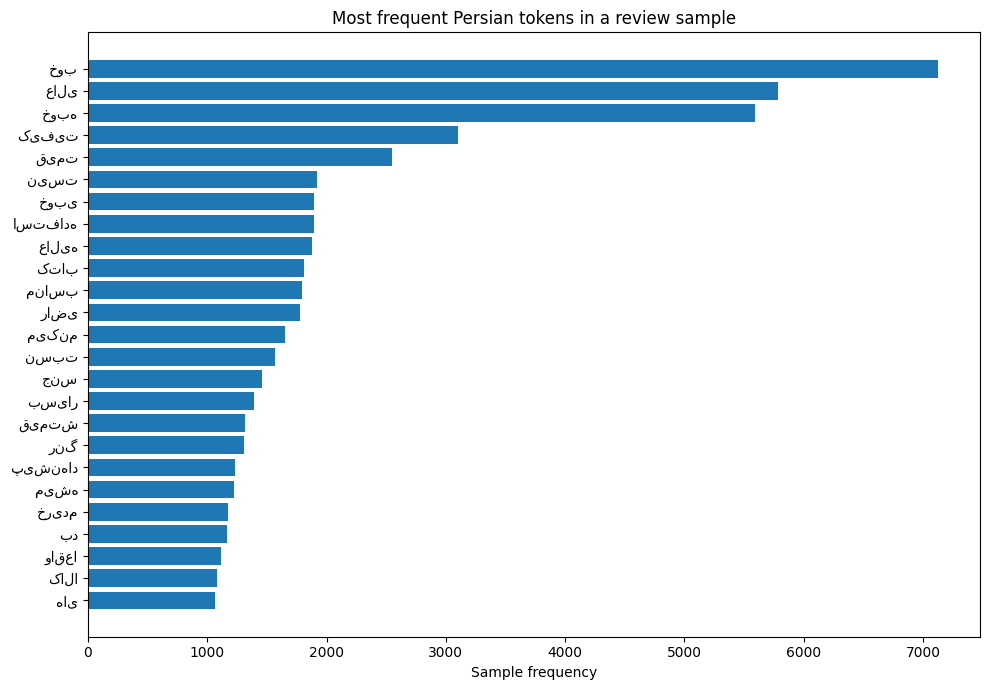

In [22]:
token_texts = con.execute("""
SELECT review_text
FROM comments_clean
WHERE review_text IS NOT NULL AND hash(id) % 211 = 0
LIMIT 30000
""").df()["review_text"].dropna().tolist()

simple_persian_stopwords = {
    "از", "به", "با", "برای", "در", "و", "که", "این", "اون", "آن", "را", "رو",
    "من", "ما", "شما", "هم", "خیلی", "یک", "یه", "اما", "ولی", "تا", "اگر",
    "است", "هست", "بود", "شد", "می", "کنم", "کرد", "کردم", "داره", "دارد"
}

counter = Counter()
for text in token_texts:
    tokens = re.findall(r"[\u0600-\u06FF]+", str(text))
    counter.update(token for token in tokens if len(token) > 1 and token not in simple_persian_stopwords)

top_tokens = pd.DataFrame(counter.most_common(25), columns=["token", "sample_frequency"])
display(top_tokens)

if not top_tokens.empty:
    plt.figure(figsize=(10, 7))
    plt.barh(top_tokens["token"].iloc[::-1], top_tokens["sample_frequency"].iloc[::-1])
    plt.title("Most frequent Persian tokens in a review sample")
    plt.xlabel("Sample frequency")
    plt.tight_layout()
    plt.show()

## 17. EDA on the joined product–review data

These analyses require matched product metadata. They use the joined view and therefore include only reviews with a matching product wherever a category or brand is required.

For recommendation percentages, the denominator is **labeled reviews only**. A missing label is not treated as a negative or as `no_idea`. Very small groups can produce unstable percentages, so brand/category comparisons below use minimum sample-size thresholds.

,category,matched_reviews,labeled_reviews,recommended_reviews,not_recommended_reviews,no_idea_reviews,recommended_percentage
0,اسباب بازی,414786,346539,265933,41385,39221,76.74
1,مراقبت پوست,392099,330283,265222,23973,41088,80.30
2,لباس مردانه,275263,239879,170783,37615,31481,71.20
3,لباس زنانه,246104,215916,154503,30520,30893,71.56
4,اکسسوری زنانه و مردانه,238217,204329,154221,24472,25636,75.48
5,نوشت افزار,226662,199268,164689,15193,19386,82.65
6,برس‌ها و تجهیزات آرایشی,212985,188894,145838,19610,23446,77.21
7,شامپو و مراقبت مو,212639,178594,141062,14513,23019,78.98
8,کتاب شعر و ادبیات,172174,146813,131405,4853,10555,89.51
9,دفتر و کاغذ و مقوا,152332,134232,114806,7353,12073,85.53


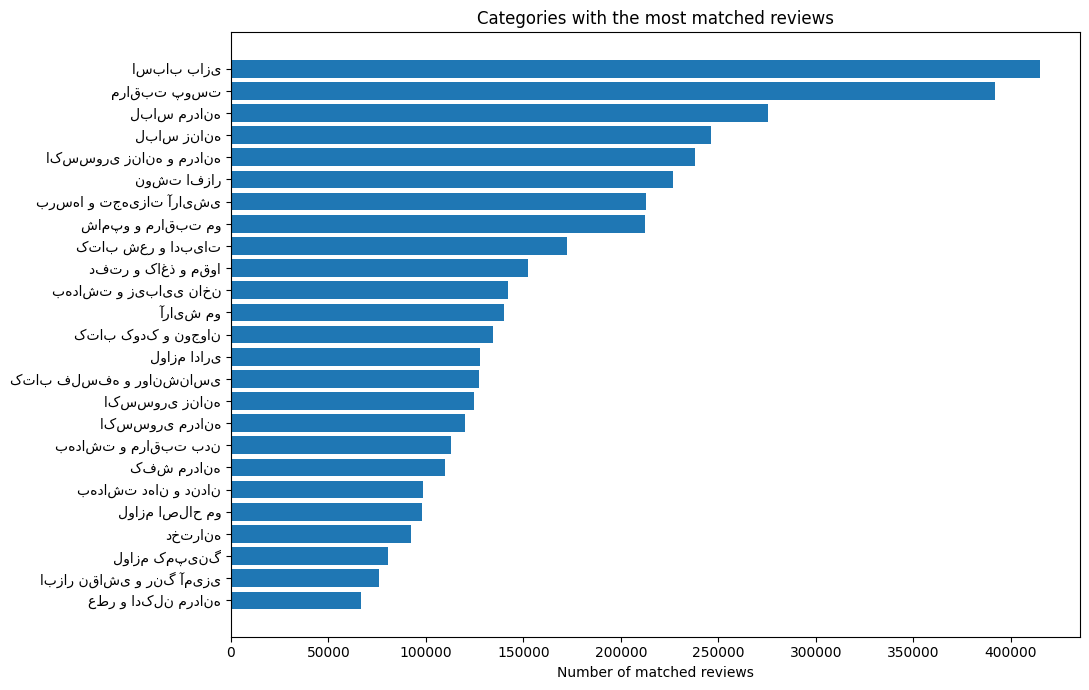

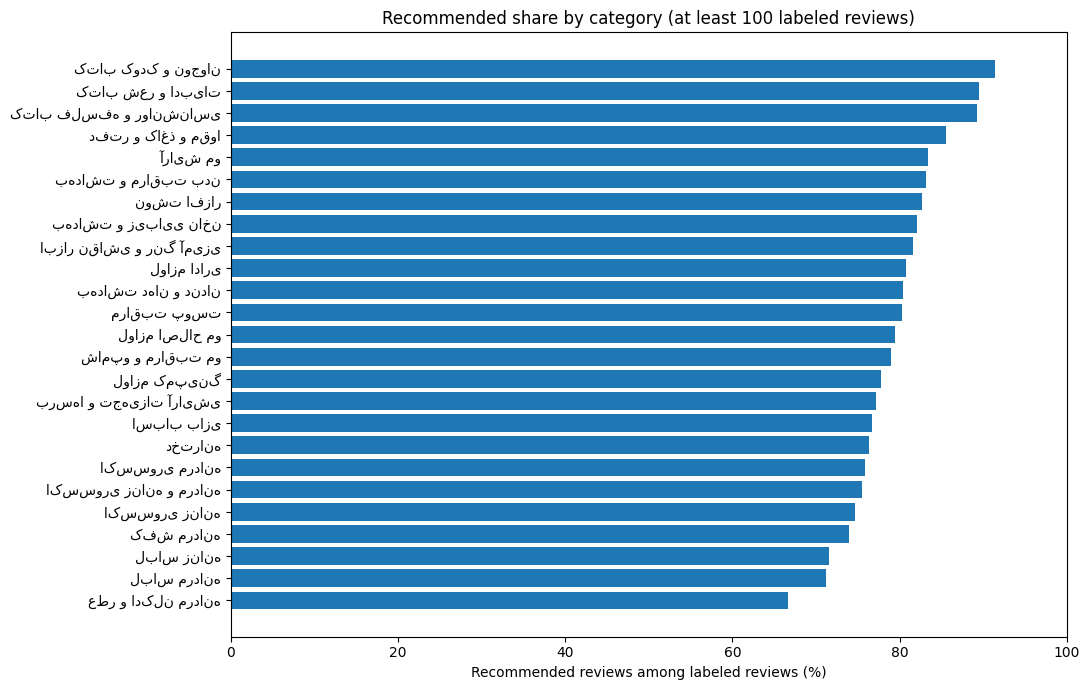

In [23]:
category_review_eda = con.execute("""
SELECT
    COALESCE(product_category1, 'Unknown') AS category,
    COUNT(*) AS matched_reviews,
    COUNT(recommendation_status) FILTER (
        WHERE recommendation_status IN ('recommended', 'not_recommended', 'no_idea')
    ) AS labeled_reviews,
    COUNT(*) FILTER (WHERE recommendation_status = 'recommended') AS recommended_reviews,
    COUNT(*) FILTER (WHERE recommendation_status = 'not_recommended') AS not_recommended_reviews,
    COUNT(*) FILTER (WHERE recommendation_status = 'no_idea') AS no_idea_reviews,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE recommendation_status = 'recommended') /
        NULLIF(COUNT(recommendation_status) FILTER (
            WHERE recommendation_status IN ('recommended', 'not_recommended', 'no_idea')
        ), 0), 2
    ) AS recommended_percentage
FROM joined_reviews
WHERE product_category1 IS NOT NULL
GROUP BY 1
HAVING COUNT(*) >= 100
ORDER BY matched_reviews DESC
LIMIT 25
""").df()

display(category_review_eda)

category_plot = category_review_eda.sort_values("matched_reviews", ascending=True)
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(category_plot["category"], category_plot["matched_reviews"])
ax.set_title("Categories with the most matched reviews")
ax.set_xlabel("Number of matched reviews")
plt.tight_layout()
plt.show()

category_rate_plot = category_review_eda[
    category_review_eda["labeled_reviews"] >= 100
].sort_values("recommended_percentage", ascending=True)
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(category_rate_plot["category"], category_rate_plot["recommended_percentage"])
ax.set_title("Recommended share by category (at least 100 labeled reviews)")
ax.set_xlabel("Recommended reviews among labeled reviews (%)")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

,brand,matched_reviews,rated_reviews,average_review_rate,labeled_reviews,recommended_percentage
0,متفرقه,2883361,2883361,3.628,2468296,75.78
1,مای,43512,43512,3.910,38078,82.37
2,بایو آکوا,38425,38425,4.042,32656,79.65
3,مارال,28181,28181,3.775,24856,84.56
4,انتشارات پرتقال,25469,25469,3.585,20204,93.18
5,مستر راد,24801,24801,4.364,21723,87.64
6,اسکمی,24197,24197,3.924,19705,84.61
7,آریان نخ باف,23679,23679,3.696,20775,84.63
8,بیول,23490,23490,3.816,20521,83.51
9,نشر افق,22109,22109,3.288,18869,93.05


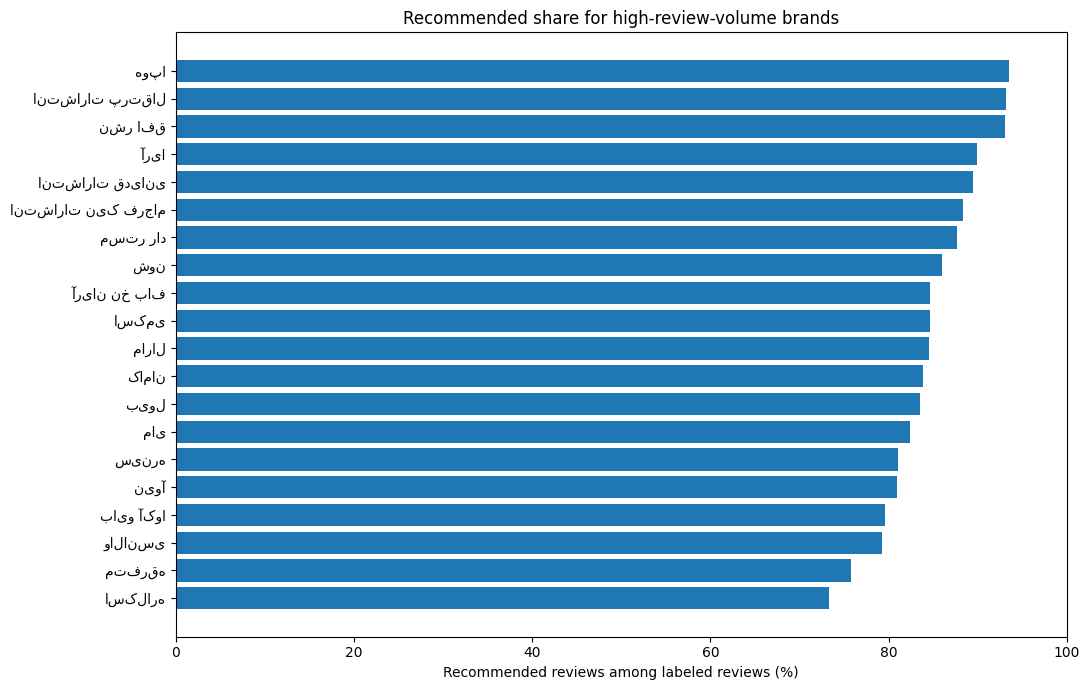

Products with many reviews (at least 100)


,product_id,product_title,product_category1,product_brand,product_price,review_count,labeled_reviews,recommended_percentage
0,2156856,استیک ضد تعریق زنانه لیدی اسپید مدل invisible dry وزن 45 گرم,ضد تعریق,لیدی اسپید استیک,1255000.0,279,255,84.71
1,3392906,خمیر دندان ضد حساسیت سیگنال مدل Original وزن 100 گرم,بهداشت دهان و دندان,سیگنال,633000.0,250,220,82.73
2,82098,شامپو تقویت کننده و ضد ریزش مو فولیکا حجم 200 میلی لیتر,شامپو و مراقبت مو,فولیکا,651600.0,238,228,86.40
3,4012333,تونر پاک کننده صورت لافارر مدل مولتی اکتیو مناسب پوست های چرب و مختلط حجم 170 میلی لیتر,مراقبت پوست,لافارر,509600.0,233,225,90.22
4,5715766,فلوئید ضد آفتاب مای مدل Hyaluronic Acid حجم 50 میلی لیتر,مراقبت پوست,مای,1501000.0,233,227,90.75
5,7291752,کرم مرطوب کننده و آبرسان ایباگ مدل شیر گاو وزن 80 گرم,مراقبت پوست,ایباگ,515000.0,232,224,80.36
6,715154,کرم ضدآفتاب و ضد لک بی رنگ لافارر مدل SPF 30 مناسب پوست های چرب حجم 40 میلی لیتر,مراقبت پوست,لافارر,2280500.0,221,218,90.37
7,471187,شامپو تقویت کننده و ضد ریزش سریتا مدل کافئین مناسب برای انواع مو حجم 200 میلی لیتر,شامپو و مراقبت مو,سریتا,878000.0,221,212,81.13
8,4545846,کرم آبرسان راکوتن مدل Prebiotic مناسب پوست های چرب و مختلط,مراقبت پوست,راکوتن,1473000.0,220,217,87.10
9,6496858,روغن حجم‌دهنده و سفت کننده گیاه قانون مدل زالو حجم 30 میلی لیتر,بهداشت جنسی,گیاه قانون,900000.0,219,205,51.22


In [24]:
brand_review_eda = con.execute("""
SELECT
    COALESCE(product_brand, 'Unknown') AS brand,
    COUNT(*) AS matched_reviews,
    COUNT(rate) AS rated_reviews,
    ROUND(AVG(rate), 3) AS average_review_rate,
    COUNT(*) FILTER (WHERE recommendation_status IN (
        'recommended', 'not_recommended', 'no_idea'
    )) AS labeled_reviews,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE recommendation_status = 'recommended') /
        NULLIF(COUNT(recommendation_status) FILTER (
            WHERE recommendation_status IN ('recommended', 'not_recommended', 'no_idea')
        ), 0), 2
    ) AS recommended_percentage
FROM joined_reviews
WHERE product_brand IS NOT NULL
GROUP BY 1
HAVING COUNT(*) >= 500
ORDER BY matched_reviews DESC
LIMIT 20
""").df()

display(brand_review_eda)

if not brand_review_eda.empty:
    brand_plot = brand_review_eda.sort_values("recommended_percentage", ascending=True)
    fig, ax = plt.subplots(figsize=(11, 7))
    ax.barh(brand_plot["brand"], brand_plot["recommended_percentage"])
    ax.set_title("Recommended share for high-review-volume brands")
    ax.set_xlabel("Recommended reviews among labeled reviews (%)")
    ax.set_xlim(0, 100)
    plt.tight_layout()
    plt.show()

product_review_volume = con.execute("""
SELECT
    product_id,
    product_title,
    product_category1,
    product_brand,
    product_price,
    COUNT(*) AS review_count,
    COUNT(*) FILTER (WHERE recommendation_status IN (
        'recommended', 'not_recommended', 'no_idea'
    )) AS labeled_reviews,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE recommendation_status = 'recommended') /
        NULLIF(COUNT(recommendation_status) FILTER (
            WHERE recommendation_status IN ('recommended', 'not_recommended', 'no_idea')
        ), 0), 2
    ) AS recommended_percentage
FROM joined_reviews
WHERE product_id IS NOT NULL
GROUP BY product_id, product_title, product_category1, product_brand, product_price
HAVING COUNT(*) >= 100
ORDER BY review_count DESC
LIMIT 30
""").df()

print("Products with many reviews (at least 100)")
display(product_review_volume)

### Product review volume versus recommendation share

Products with many reviews but a relatively low recommendation percentage may be useful candidates for deeper review analysis. This chart should not be interpreted as a definitive product-quality ranking: products differ in category, buyer mix, review count, and label availability. It is a shortlist for inspection, not a causal conclusion.

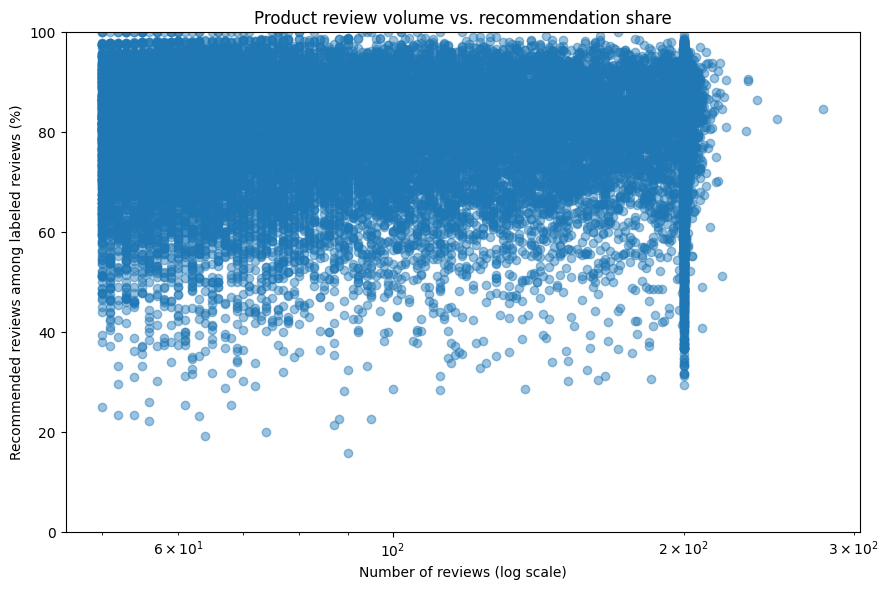

In [25]:
scatter_data = con.execute("""
SELECT
    product_id,
    COUNT(*) AS review_count,
    COUNT(*) FILTER (WHERE recommendation_status IN (
        'recommended', 'not_recommended', 'no_idea'
    )) AS labeled_reviews,
    100.0 * COUNT(*) FILTER (WHERE recommendation_status = 'recommended') /
        NULLIF(COUNT(recommendation_status) FILTER (
            WHERE recommendation_status IN ('recommended', 'not_recommended', 'no_idea')
        ), 0) AS recommended_percentage
FROM joined_reviews
WHERE product_id IS NOT NULL
GROUP BY product_id
HAVING COUNT(*) >= 50
   AND COUNT(recommendation_status) FILTER (
       WHERE recommendation_status IN ('recommended', 'not_recommended', 'no_idea')
   ) >= 30
""").df()

if not scatter_data.empty:
    plt.figure(figsize=(9, 6))
    plt.scatter(scatter_data["review_count"], scatter_data["recommended_percentage"], alpha=0.45)
    plt.xscale("log")
    plt.ylim(0, 100)
    plt.title("Product review volume vs. recommendation share")
    plt.xlabel("Number of reviews (log scale)")
    plt.ylabel("Recommended reviews among labeled reviews (%)")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough matched products met the minimum review-count thresholds.")

## 18. Save EDA summary tables and final data products

The full cleaned tables are saved in Parquet format, which is more compact and faster to query than repeatedly loading the original CSVs. The DuckDB database stores the SQL views and can be reused in later notebooks.

The complete join remains a view named `joined_reviews`. For later tasks, query this view or create a filtered/aggregated table. Avoid exporting the entire joined table unless there is a clear need and enough disk space.

In [26]:
TABLES_TO_SAVE = {
    "products_missingness.csv": products_schema_report,
    "comments_missingness.csv": comments_schema_report,
    "product_categories.csv": product_category_counts,
    "top_brands_by_product_count.csv": top_brands,
    "recommendation_status_counts.csv": recommendation_counts,
    "reviews_by_jalali_year.csv": year_counts,
    "reviews_by_jalali_month.csv": month_counts,
    "category_review_eda.csv": category_review_eda,
    "brand_review_eda.csv": brand_review_eda,
    "products_with_many_reviews.csv": product_review_volume,
    "top_review_tokens_sample.csv": top_tokens
}

for filename, dataframe in TABLES_TO_SAVE.items():
    dataframe.to_csv(OUTPUT_DIR / filename, index=False, encoding="utf-8-sig")

# Save small scalar summaries too.
join_summary.to_csv(OUTPUT_DIR / "join_coverage_summary.csv", index=False, encoding="utf-8-sig")
product_price_summary.to_csv(OUTPUT_DIR / "product_price_summary.csv", index=False, encoding="utf-8-sig")
product_rating_summary.to_csv(OUTPUT_DIR / "product_rating_summary.csv", index=False, encoding="utf-8-sig")
known_target_summary.to_csv(OUTPUT_DIR / "recommendation_label_summary.csv", index=False, encoding="utf-8-sig")
review_text_summary.to_csv(OUTPUT_DIR / "review_text_summary.csv", index=False, encoding="utf-8-sig")

print("Saved EDA tables to:", OUTPUT_DIR.resolve())
print("Main cleaned outputs:")
print(" -", PRODUCTS_CLEAN)
print(" -", COMMENTS_CLEAN)
print(" -", DATABASE_PATH)
print(" - DuckDB views: products_clean, comments_clean, joined_reviews")

Saved EDA tables to: C:\Users\BiaDigi.com\Documents\bootcamp-quera-files\project\LLM\processed_full
Main cleaned outputs:
 - processed_full\products_clean.parquet
 - processed_full\comments_clean.parquet
 - processed_full\digikala_analysis.duckdb
 - DuckDB views: products_clean, comments_clean, joined_reviews


## 19. Conclusions and decisions for the remaining project

Use the actual tables and charts produced above to write the numerical findings in your report. Do not copy sample-file percentages into the full-data report.

### Recommendations for the next project parts

**Product search and discovery**
- Use one consolidated row per product ID.
- Use `title_fa`, category, brand, `Price`, `Rate_usable`, and `Rate_cnt` as structured product fields.
- Keep `Price_min_observed` and `Price_max_observed` for transparency when source records disagreed.
- Treat missing prices/ratings as unavailable, not as zero.

**Review Q&A and evidence retrieval**
- Retrieve from `review_text` or `review_text_with_aspects` depending on the experiment.
- Always retain `id` and `product_id` so evidence can be cited.
- Use only matched product IDs when claiming that a review belongs to a particular product.
- Keep unmatched reviews for generic review-level analysis, but do not attach them to an unverified product.

**Product/category/brand analytics**
- Aggregate from `joined_reviews` after validating join coverage.
- Report the number of labeled reviews beside recommendation percentages.
- Use a minimum support threshold; a percentage from a handful of reviews is unstable.
- For common complaints, use review text/aspect analysis rather than relying only on raw frequent tokens.

**Recommendation-status classifier**
- The target classes are `recommended`, `not_recommended`, and `no_idea`.
- Exclude only rows with missing or unexpected target values from supervised training; do not relabel missing values as `no_idea`.
- Start with `review_text` as a text-only baseline; compare `review_text_with_aspects` as a separate experiment.
- Do not feed `rate`, likes/dislikes, product metadata, or the label itself into a model described as text-only.
- Use a product-group-aware split (for example, `StratifiedGroupKFold` grouped by `product_id`) to reduce leakage from reviews of the same product across train/test. Report Macro F1 and per-class metrics.

### Important limitations to state in the report

- The representative product price is a median of observed positive values, not a verified live price.
- The Jalali date columns are extracted components, not Gregorian timestamps.
- Persian normalization is intentionally conservative; tokenization, stopword removal, stemming, and embedding-specific normalization should be evaluated separately.
- Outliers are flagged, not automatically removed.
- Repeated review IDs with conflicting content are reported and need a deliberate policy before using review IDs as unique evidence references.
- Joined analyses depend on the measured full-data match rate. Do not assume that all comments have matching products.

This completes the reproducible full-dataset workflow for Part 1.